In [1]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
ticker = yf.Ticker("SPY")
expirations = ticker.options
print("Available expirations:", expirations)

Available expirations: ('2026-04-13', '2026-04-14', '2026-04-15', '2026-04-16', '2026-04-17', '2026-04-20', '2026-04-24', '2026-04-30', '2026-05-01', '2026-05-08', '2026-05-15', '2026-05-22', '2026-05-29', '2026-06-18', '2026-06-30', '2026-07-17', '2026-07-31', '2026-08-21', '2026-08-31', '2026-09-18', '2026-09-30', '2026-12-18', '2026-12-31', '2027-01-15', '2027-03-19', '2027-03-31', '2027-06-17', '2027-09-17', '2027-12-17', '2028-01-21', '2028-06-16', '2028-12-15')


In [3]:
exp = expirations[2]
chain = ticker.option_chain(exp)

In [4]:
calls = chain.calls
puts = chain.puts

In [5]:
print(calls.columns.tolist())

['contractSymbol', 'lastTradeDate', 'strike', 'lastPrice', 'bid', 'ask', 'change', 'percentChange', 'volume', 'openInterest', 'impliedVolatility', 'inTheMoney', 'contractSize', 'currency']


In [6]:
# historical price data for realized vol
spy = yf.download("SPY", start="2020-01-01", end="2025-12-31")

# implied volatility index
vix = yf.download("^VIX", start="2020-01-01", end="2025-12-31")


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


In [7]:
spy.head()

Price,Close,High,Low,Open,Volume
Ticker,SPY,SPY,SPY,SPY,SPY
Date,,,,,
2020-01-02,296.888153,296.906448,294.749706,295.672721,59151200
2020-01-03,294.640015,295.764082,293.442850,293.497680,77709700
2020-01-06,295.764130,295.846374,292.766617,292.885424,55653900
2020-01-07,294.932587,295.672817,294.484772,295.197588,40496400
2020-01-08,296.504333,297.719765,294.877650,295.124385,68296000


In [8]:
vix.head()

Price,Close,High,Low,Open,Volume
Ticker,^VIX,^VIX,^VIX,^VIX,^VIX
Date,,,,,
2020-01-02,12.47,13.720000,12.42,13.46,0
2020-01-03,14.02,16.200001,13.13,15.01,0
2020-01-06,13.85,16.389999,13.54,15.45,0
2020-01-07,13.79,14.460000,13.39,13.84,0
2020-01-08,13.45,15.240000,12.83,15.16,0


In [9]:
vix2 = vix[vix.index >= "2020-01-01"]
vix2.head()

Price,Close,High,Low,Open,Volume
Ticker,^VIX,^VIX,^VIX,^VIX,^VIX
Date,,,,,
2020-01-02,12.47,13.720000,12.42,13.46,0
2020-01-03,14.02,16.200001,13.13,15.01,0
2020-01-06,13.85,16.389999,13.54,15.45,0
2020-01-07,13.79,14.460000,13.39,13.84,0
2020-01-08,13.45,15.240000,12.83,15.16,0


In [10]:
#building features from raw pricing data

def vol_features(rv_df, iv_df):
    # Calculate historical volatility (realized volatility)
    df = rv_df[["Close"]].copy()
    df["log_return"] = np.log(df["Close"] / df["Close"].shift(1))

    # Realized volatility as rolling std of log returns (annualized)
    df["realized_vol5"] = df["log_return"].rolling(window=5).std() * np.sqrt(252)
    df["realized_vol10"] = df["log_return"].rolling(window=10).std() * np.sqrt(252)
    df["realized_vol21"] = df["log_return"].rolling(window=21).std() * np.sqrt(252)

    # Volatility of volatility (already on annualized RV scale; no extra annualization)
    df["vol_of_vol5"] = df["realized_vol5"].rolling(window=5).std()

    # Parkinson Volatility (High-Low estimator)
    df["parkinson"] = (
        np.log(rv_df["High"] / rv_df["Low"]) / (2 * np.sqrt(np.log(2)))
    ).rolling(21).mean() * np.sqrt(252)

    # Garman-Klass Volatility (Open-High-Low-Close)
    hl = np.log(rv_df["High"] / rv_df["Low"])
    co = np.log(rv_df["Close"] / rv_df["Open"])
    gk_var = 0.5 * (hl ** 2) - (2 * np.log(2) - 1) * (co ** 2)
    df["gk_vol"] = np.sqrt(252 * gk_var.rolling(21).mean().clip(lower=0))

    # HAR (Heterogeneous Autoregressive) features
    # Daily, Weekly, Monthly RV lags — standard in vol forecasting
    df["rv_lag1"]  = df["realized_vol5"].shift(1)
    df["rv_lag5"]  = df["realized_vol5"].shift(5)
    df["rv_lag21"] = df["realized_vol5"].shift(21)

    # VIX as external feature (if available)
    if iv_df is not None:
        df["vix"] = iv_df["Close"].reindex(df.index, method="ffill")
        df["vix_change"] = df["vix"].pct_change()

    # Price momentum
    df["mom_5d"]  = df["Close"].pct_change(5)
    df["mom_21d"] = df["Close"].pct_change(21)

    # Target: 21-trading-day-ahead realized vol
    df["target_rv"] = df["realized_vol21"].shift(-21)

    return df.dropna()

In [11]:
spy.columns = spy.columns.get_level_values(0)
vix2.columns = vix2.columns.get_level_values(0)

In [12]:
spy.head()

Price,Close,High,Low,Open,Volume
Date,,,,,
2020-01-02,296.888153,296.906448,294.749706,295.672721,59151200
2020-01-03,294.640015,295.764082,293.442850,293.497680,77709700
2020-01-06,295.764130,295.846374,292.766617,292.885424,55653900
2020-01-07,294.932587,295.672817,294.484772,295.197588,40496400
2020-01-08,296.504333,297.719765,294.877650,295.124385,68296000


In [13]:
vix2.head()

Price,Close,High,Low,Open,Volume
Date,,,,,
2020-01-02,12.47,13.720000,12.42,13.46,0
2020-01-03,14.02,16.200001,13.13,15.01,0
2020-01-06,13.85,16.389999,13.54,15.45,0
2020-01-07,13.79,14.460000,13.39,13.84,0
2020-01-08,13.45,15.240000,12.83,15.16,0


In [14]:
data = vol_features(spy, vix2)

In [15]:
data.head()

Price,Close,log_return,realized_vol5,realized_vol10,realized_vol21,vol_of_vol5,parkinson,gk_vol,rv_lag1,rv_lag5,rv_lag21,vix,vix_change,mom_5d,mom_21d,target_rv
Date,,,,,,,,,,,,,,,,
2020-02-10,305.853180,0.007438,0.125553,0.154344,0.134006,0.043719,0.078085,0.083580,0.125535,0.179194,0.096611,15.04,-0.027796,0.032580,0.024583,0.501494
2020-02-11,306.383392,0.001732,0.100493,0.149350,0.133205,0.051044,0.078104,0.084050,0.125553,0.197924,0.072709,15.18,0.009309,0.018842,0.029321,0.590102
2020-02-12,308.357300,0.006422,0.080308,0.149224,0.132989,0.048789,0.076915,0.083670,0.100493,0.208507,0.080213,13.74,-0.094862,0.013700,0.028877,0.675546
2020-02-13,308.028259,-0.001068,0.084151,0.150793,0.132874,0.021753,0.077899,0.084328,0.080308,0.208489,0.075036,14.15,0.029840,0.009222,0.029348,0.765893
2020-02-14,308.521667,0.001601,0.056828,0.095641,0.132838,0.025501,0.077526,0.084217,0.084151,0.125535,0.071921,13.68,-0.033216,0.016255,0.028672,0.800411


### Exploratory Data Analysis

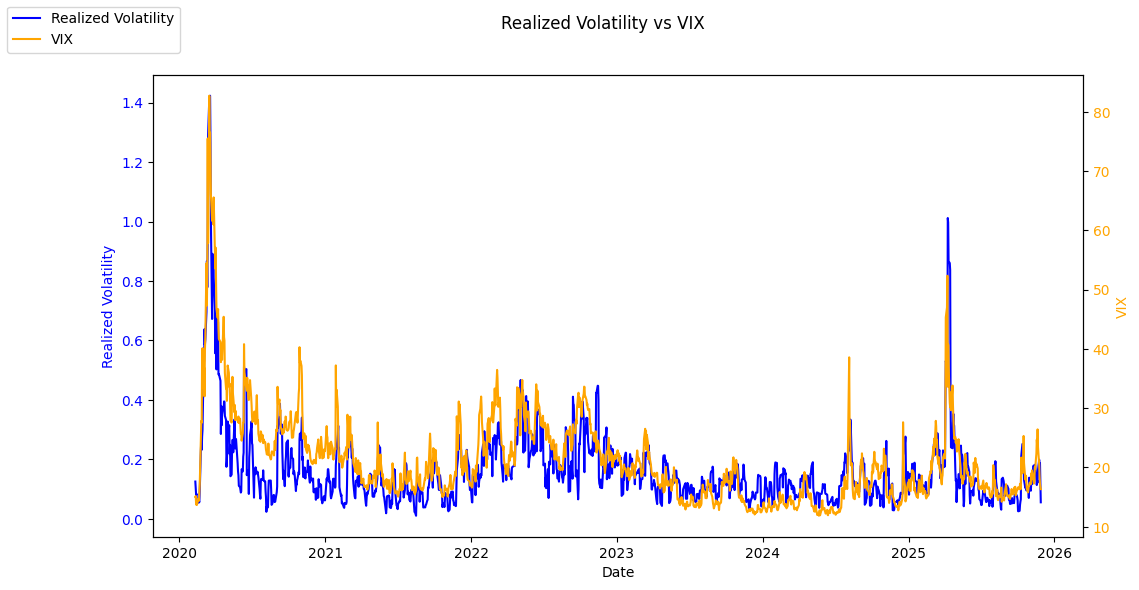

In [16]:
fig, ax1 = plt.subplots(figsize=(12, 6))
ax1.plot(data.index, data["realized_vol5"], label="Realized Volatility", color="blue")
ax1.set_xlabel("Date")
ax1.set_ylabel("Realized Volatility", color="blue")
ax1.tick_params(axis="y", labelcolor="blue")
ax2 = ax1.twinx()
ax2.plot(data.index, data["vix"], label="VIX", color="orange")
ax2.set_ylabel("VIX", color="orange")
ax2.tick_params(axis="y", labelcolor="orange")
fig.suptitle("Realized Volatility vs VIX")
fig.legend(loc="upper left")
plt.show()

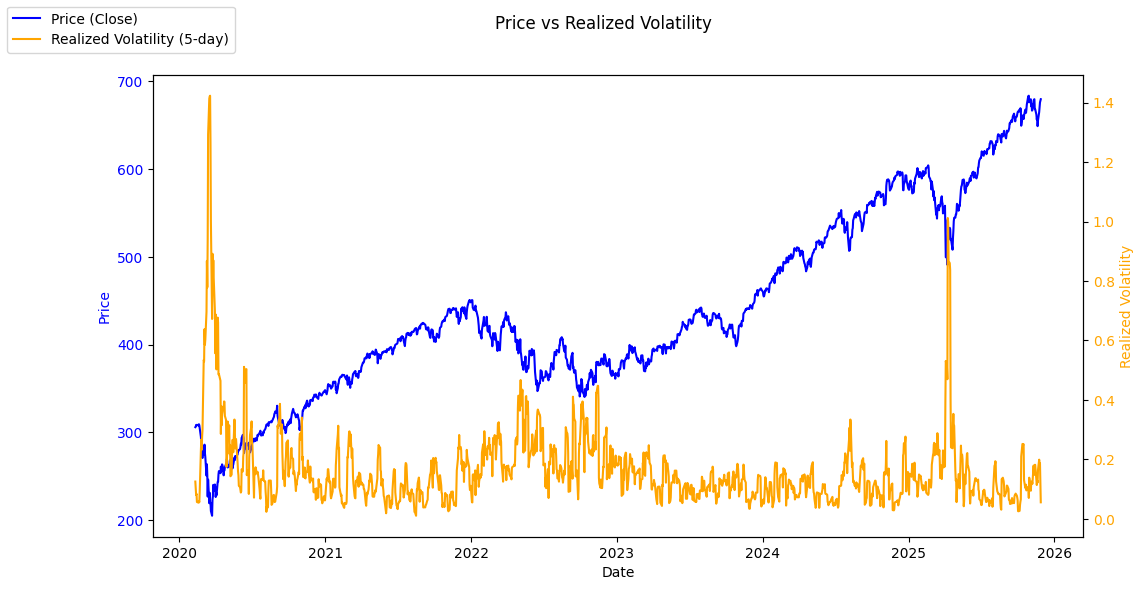

In [17]:
#exploring behaviour of realized volatility time series
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(data.index, data["Close"], label="Price (Close)", color="blue")
ax.set_xlabel("Date")
ax.set_ylabel("Price", color="blue")
ax.tick_params(axis="y", labelcolor="blue")
ax2 = ax.twinx()
ax2.plot(data.index, data["realized_vol5"], label="Realized Volatility (5-day)", color="orange")
ax2.set_ylabel("Realized Volatility", color="orange")
ax2.tick_params(axis="y", labelcolor="orange")
fig.suptitle("Price vs Realized Volatility")
fig.legend(loc="upper left")
plt.show()

In [18]:
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import warnings
warnings.filterwarnings("ignore")

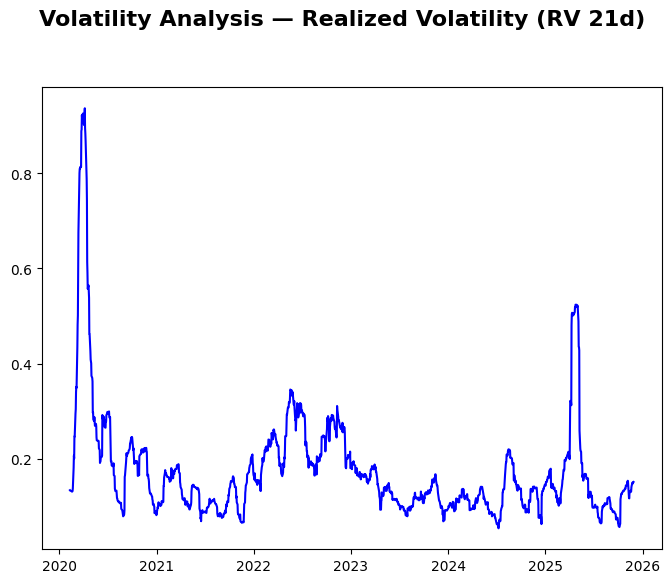

In [19]:
#stationarity test of rv_21d
series = data["realized_vol21"].copy()

fig = plt.figure(figsize=(8, 6))
fig.suptitle("Volatility Analysis — Realized Volatility (RV 21d)",
             fontsize=16, fontweight="bold", y=1.01)
plt.plot(series, label="RV 21d", color="blue")
plt.show()

In [20]:
adf_stat, p_value, _, _, critical_values, _ = adfuller(series.dropna(), autolag="AIC")

In [21]:
p_value

np.float64(6.939565515259602e-07)

with p-value < 0.05, the trend is the realized volatity (21 rolling days) is stationary

In [22]:
#Seasonal Decomposition of RV 21d
stl        = STL(series.dropna(), period=252, seasonal=13, robust=True)
stl_result = stl.fit()

# Strength scores
trend_strength    = max(0, 1 - np.var(stl_result.resid) /
                              np.var(stl_result.trend + stl_result.resid))
seasonal_strength = max(0, 1 - np.var(stl_result.resid) /
                              np.var(stl_result.seasonal + stl_result.resid))

In [23]:
print(f"  Trend Strength    : {trend_strength:.4f}  (>0.6 = strong)")
print(f"  Seasonal Strength : {seasonal_strength:.4f}  (>0.4 = notable)")

  Trend Strength    : 0.2114  (>0.6 = strong)
  Seasonal Strength : 0.0011  (>0.4 = notable)


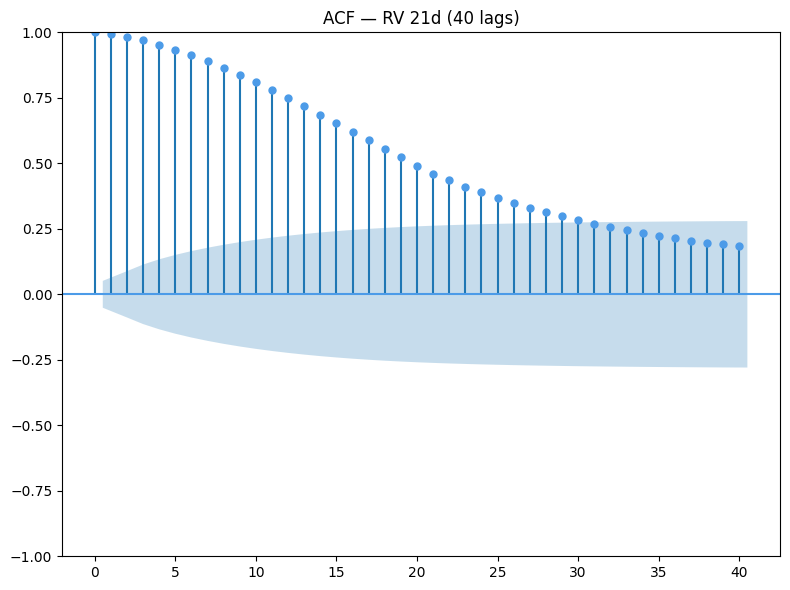

In [24]:
fig, ax4 = plt.subplots(figsize=(8, 6))
plot_acf( series.dropna(), lags=40, ax=ax4,
          color="#4C9BE8", title="ACF — RV 21d (40 lags)")
plt.tight_layout()
plt.show()

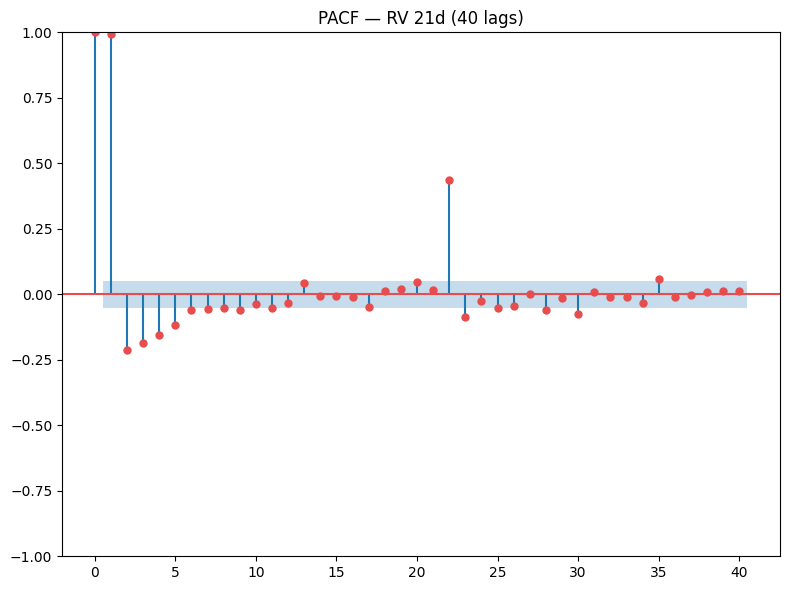

In [25]:
fig, ax5 = plt.subplots(figsize=(8, 6))
plot_pacf(series.dropna(), lags=40, ax=ax5,
          color="#E84C4C", title="PACF — RV 21d (40 lags)")
plt.tight_layout()
plt.show()

In [26]:
data.to_csv("/Users/josephineamponsah/Documents/price_volatility_prediction/data/processed_vol_features.csv")